Projeto Integrador II • PUC-SP

# 1. Visão Computacional
A etapa de visão computacional tem como objetivo extrair informações das imagens anexadas aos chamados de suporte.

A proposta é utilizar o BLIP, um modelo pré-treinado capaz de relacionar imagens e linguagem natural.

A aplicação escolhida é chamada Image Captioning, ou geração automática de legendas. Em termos simples, queremos transformar uma imagem em uma descrição que possa ser utilizada posteriormente pela solução multimodal.

Por exemplo:

- Fotografia de um computador aberto ->	"Computador com componentes internos visíveis."

- Fotografia de um roteador ->	"Dispositivo de rede com indicadores luminosos."

- Fotografia de uma tela	-> "Monitor exibindo uma mensagem de erro."

## 2. Preparar o ambiente

Encontramos a raiz do projeto, lemos a configuração de visão e importamos funções diretamente de `src/models/vision.py` — não uma reimplementação didática.

In [28]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import yaml

# Procura a raiz a partir da pasta atual ou de suas pastas-pai.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/models/vision.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Abra o notebook na raiz do projeto (contendo src/ e data/).")

sys.path.insert(0, str(ROOT))
from src.models.vision import sequence_confidence, caption_partitions
from src.models.feature_common import image_records

config_file = ROOT / "src/config/models.yaml"
all_config = yaml.safe_load(config_file.read_text(encoding="utf-8"))
vision_config = all_config["modelos"]["visao_computacional"]

print("Raiz:", ROOT)
print("Modelo configurado:", vision_config["fonte"]["nome"])
print("Treinamento habilitado:", vision_config["training"]["enabled"])

Raiz: c:\Users\Hiago\Documents\GitHub\ProjetoIntegrador-II
Modelo configurado: Salesforce/blip-image-captioning-base
Treinamento habilitado: True


## 3. Ver uma imagem real

O modelo recebe pixels da imagem. Nesta etapa só abrimos a imagem e a exibimos; ainda não há previsão.

Imagens reais disponíveis: 26


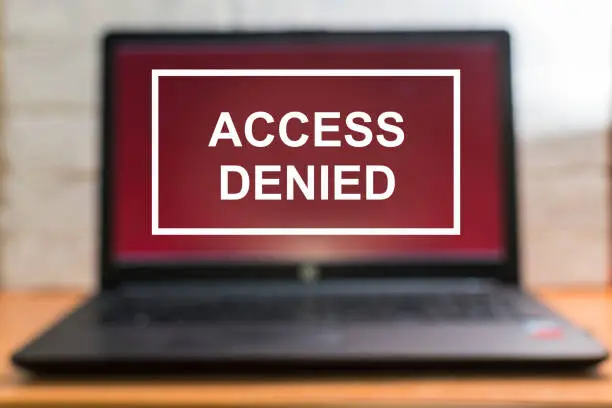

Arquivo: access_denied.png | tamanho: (612, 408)


In [29]:
images_dir = ROOT / "data/images"
image_paths = sorted(images_dir.glob("*.png"))
print(f"Imagens reais disponíveis: {len(image_paths)}")

example_path = image_paths[0]
with Image.open(example_path) as img:
    display(img.convert("RGB"))
print("Arquivo:", example_path.name, "| tamanho:", Image.open(example_path).size)

## 4. Executar a validação real de hashes e legendas

`caption_partitions` é a função do `vision.py` que valida as legendas humanas, recalcula os hashes e verifica se uma mesma imagem foi parar em mais de uma partição. Para uma demonstração curta, dividimos as imagens anotadas em dois grupos sem sobreposição: `train` e `validation`.

Isso **não é o split oficial de avaliação** do projeto; é uma amostra didática para executar a função e observar seu comportamento.

In [30]:
annotations_path = ROOT / vision_config["training"]["captions_file"]
annotations = pd.read_csv(annotations_path)

# A coluna image_path usa caminhos relativos à pasta data/.
paths = annotations["image_path"].astype(str).tolist()
cut = max(1, int(len(paths) * 0.7))

train_demo = pd.DataFrame({"image_path": paths[:cut]})
validation_demo = pd.DataFrame({"image_path": paths[cut:]})

demo_partitions = caption_partitions(
    vision_config,
    {"train": train_demo, "validation": validation_demo},
    ROOT
)

for name, frame in demo_partitions.items():
    print(f"{name}: {len(frame)} imagens")
    display(frame[["path", "sha256"] + (["caption"] if "caption" in frame else [])].head(3))

train: 18 imagens


,path,sha256,caption
0,C:\Users\Hiago\Documents\GitHub\ProjetoIntegra...,8105589f2c78c538ee13af1b76dea6dfb0930372860cac...,A laptop screen displays a red access denied m...
1,C:\Users\Hiago\Documents\GitHub\ProjetoIntegra...,561a928fbcf2336af41bcbe181f40cd398ab5c65cc2d36...,A web browser displays the Gmail logo on a whi...
2,C:\Users\Hiago\Documents\GitHub\ProjetoIntegra...,7cded9cd6c5b98fdeb9833a49c81bd4016fd753e7a349e...,An open desktop computer case shows internal f...


validation: 8 imagens


,path,sha256,caption
0,C:\Users\Hiago\Documents\GitHub\ProjetoIntegra...,3d7ff9d021f7974dab0ff0e4cd1461b37d5063bf4dd39b...,A router with two antennas is connected to net...
1,C:\Users\Hiago\Documents\GitHub\ProjetoIntegra...,487d2aecd94e6f0141902754c5b7c29be36c2af50dd4c8...,A finger points at numeric cells in a spreadsh...
2,C:\Users\Hiago\Documents\GitHub\ProjetoIntegra...,4570b03e21e1b21f9d7351b886f96768259c821b1a56a2...,A pen rests on a printed payroll table contain...


**O que acabou de acontecer?**

- O arquivo real foi aberto e seu SHA-256 foi calculado.
- O hash foi comparado com `image_sha256` do CSV de anotações.
- As legendas foram associadas às imagens pelo hash, não apenas pelo nome do arquivo.
- A função rejeitaria imagens repetidas entre treino e validação ou legendas inconsistentes.

## 5. Rodar o BLIP

Esta seção chama a classe `ImageCaptioner` do próprio `vision.py`. Ela requer que `transformers` esteja instalado e que os pesos do modelo estejam disponíveis ou possam ser baixados.

A classe completa é pensada para ser usada pelo pipeline de features do projeto. Para a demonstração, carregamos o processor e o modelo pré-treinado diretamente, com os mesmos parâmetros centrais de geração (`num_beams` e `max_new_tokens`) configurados no YAML. Assim é possível ver uma legenda real sem executar o ajuste fino, que pode levar mais tempo.

c:\Users\Hiago\Documents\GitHub\ProjetoIntegrador-II\venv312\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Hiago\.cache\huggingface\hub\models--Salesforce--blip-image-captioning-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


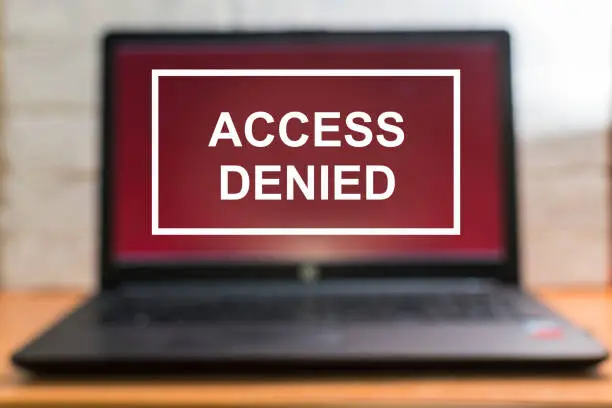

Legenda gerada pelo BLIP: a laptop with the words ace's end on it


In [31]:
RUN_BLIP = True  # mude para True quando transformers e os pesos estiverem disponíveis

if RUN_BLIP:
    import torch
    from transformers import BlipProcessor, BlipForConditionalGeneration

    model_name = vision_config["fonte"]["nome"]
    processor = BlipProcessor.from_pretrained(model_name, use_fast=False)
    model = BlipForConditionalGeneration.from_pretrained(model_name)

    device = "cuda" if torch.cuda.is_available() and vision_config.get("device", "auto") != "cpu" else "cpu"
    model.to(device).eval()

    with Image.open(example_path) as img:
        rgb = img.convert("RGB")
        inputs = processor(images=rgb, return_tensors="pt").to(device)

    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            do_sample=False,
            num_beams=vision_config["generation"]["num_beams"],
            max_new_tokens=vision_config["generation"]["max_new_tokens"]
        )

    caption = processor.decode(generated[0], skip_special_tokens=True).strip()
    display(rgb)
    print("Legenda gerada pelo BLIP:", caption)
else:
    print("Inferência desativada. Defina RUN_BLIP = True para gerar uma legenda real.")

## 6. Executar o cálculo real de `image_score`

A função `sequence_confidence` também vem diretamente de `vision.py`. Ela calcula a média geométrica das probabilidades dos tokens de conteúdo. Aqui usamos valores pequenos apenas para demonstrar a função matemática; o score abaixo **não é uma previsão do BLIP**.

In [32]:
import numpy as np

# Exemplo didático de log-probabilidades de 3 tokens:
token_probabilities = np.array([0.90, 0.75, 0.60])
log_probabilities = np.log(token_probabilities)

# IDs 10, 11 e 12 são tokens fictícios; nenhum é tratado como especial.
score = sequence_confidence(
    log_probabilities=log_probabilities,
    token_ids=np.array([10, 11, 12]),
    special_ids={0, 1, 2}
)
print("Probabilidades dos tokens:", token_probabilities)
print(f"image_score calculado pela função real: {score:.4f}")

Probabilidades dos tokens: [0.9  0.75 0.6 ]
image_score calculado pela função real: 0.7399
